# HW11 — CLIP: Caption–Image Similarity and Zero-Shot Classification on CIFAR-10

| Component | Choice |
|---|---|
| Model | OpenAI CLIP **ViT-B/32** (`openai/clip-vit-base-patch32`, Hugging Face `transformers`) |
| Data | CIFAR-10 **test** split (10,000 images, 32×32, 10 classes, 1,000 per class) |
| Part A | One caption vs. **1,000 images (100 per class)**, cosine similarity of L2-normalized embeddings |
| Part B | Zero-shot classification of all **10,000** test images; per-class accuracy + confusion matrix |
| Preprocessing | `CLIPProcessor`: resize shortest side to 224 (bicubic), center-crop 224×224, RGB, normalize with CLIP mean/std |
| Device | Apple MPS if available, else CUDA, else CPU. `SEED = 1605` (SID4) |

**Part A steps:** (1) load CLIP → (2) define the caption → (3) preprocess multiple images → (4) extract & normalize embeddings → (5) compute similarity scores → (6) visualize images with their scores → (7) document findings.

**Part B:** use CLIP as a zero-shot classifier (no CIFAR-10 training): embed one text prompt per class, assign each image to the class whose prompt embedding has the highest cosine similarity.

## 0. Setup

In [1]:
import os, random, platform, time
import numpy as np, pandas as pd, torch, matplotlib
import matplotlib.pyplot as plt
import torchvision, transformers, sklearn
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

SEED = 1605                     # SID4, per the standing course rules
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("figures", exist_ok=True); os.makedirs("data", exist_ok=True)
pd.set_option("display.width", 200)
print("python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| transformers", transformers.__version__, "| scikit-learn", sklearn.__version__, "| device", DEVICE)

python 3.13.7 | torch 2.11.0 | torchvision 0.26.0 | transformers 5.5.3 | scikit-learn 1.8.0 | device mps


## 1. Load the CLIP model

CLIP has two encoders trained contrastively on 400M image–text pairs: a ViT-B/32 image encoder and a Transformer text encoder. Both project into a shared **512-d** embedding space, where matching image/text pairs have high cosine similarity.

In [2]:
MODEL_ID = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL_ID).to(DEVICE).eval()
processor = CLIPProcessor.from_pretrained(MODEL_ID)

n_img = sum(p.numel() for p in model.vision_model.parameters()) + sum(p.numel() for p in model.visual_projection.parameters())
n_txt = sum(p.numel() for p in model.text_model.parameters()) + sum(p.numel() for p in model.text_projection.parameters())
print(f"{MODEL_ID}: {sum(p.numel() for p in model.parameters())/1e6:.1f}M params "
      f"(image tower {n_img/1e6:.1f}M, text tower {n_txt/1e6:.1f}M)")
print("embedding dim:", model.config.projection_dim, "| input resolution:", model.config.vision_config.image_size,
      "| learned logit scale (temperature^-1):", round(model.logit_scale.exp().item(), 2))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


openai/clip-vit-base-patch32: 151.3M params (image tower 87.8M, text tower 63.4M)
embedding dim: 512 | input resolution: 224 | learned logit scale (temperature^-1): 100.0


Helper functions used by both parts. `get_image_features` / `get_text_features` return the projected (512-d) embeddings; recent `transformers` versions may wrap them in an output object, so `_as_tensor` handles both. Embeddings are **L2-normalized**, so a dot product equals cosine similarity.

In [3]:
def _as_tensor(out):
    if torch.is_tensor(out):
        return out
    return out.pooler_output if getattr(out, "pooler_output", None) is not None else out[0]

def normalize(x):
    return x / x.norm(dim=-1, keepdim=True)

@torch.no_grad()
def embed_texts(texts):
    tok = processor(text=list(texts), return_tensors="pt", padding=True).to(DEVICE)
    return normalize(_as_tensor(model.get_text_features(**tok)).float()).cpu()

@torch.no_grad()
def embed_images(pil_images, batch_size=256):
    feats = []
    for i in range(0, len(pil_images), batch_size):
        px = processor(images=pil_images[i:i + batch_size], return_tensors="pt")["pixel_values"].to(DEVICE)
        feats.append(normalize(_as_tensor(model.get_image_features(pixel_values=px)).float()).cpu())
    return torch.cat(feats)

## 2. Load CIFAR-10 and sample 100 images per class

The CIFAR-10 test split has exactly 1,000 images per class. For Part A we draw **100 per class (1,000 images)** with a fixed seed. Part B uses all 10,000.

10000 test images | classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
per-class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Part A subset: 1000 images; per class: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]


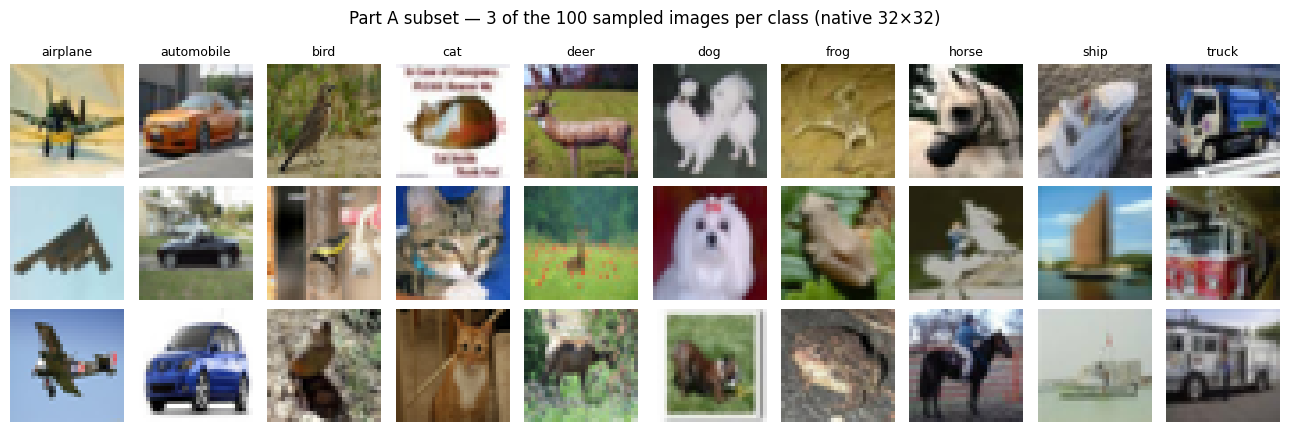

In [4]:
test = torchvision.datasets.CIFAR10("data", train=False, download=True)
CLASSES = test.classes
labels_all = np.array(test.targets)
images_all = [test[i][0] for i in range(len(test))]        # PIL 32x32 RGB
print(len(images_all), "test images | classes:", CLASSES)
print("per-class counts:", np.bincount(labels_all).tolist())

rng = np.random.default_rng(SEED)
N_PER_CLASS = 100
idx_A = np.concatenate([rng.choice(np.where(labels_all == c)[0], N_PER_CLASS, replace=False) for c in range(10)])
imgs_A, y_A = [images_all[i] for i in idx_A], labels_all[idx_A]
print("Part A subset:", len(imgs_A), "images; per class:", np.bincount(y_A).tolist())

fig, axes = plt.subplots(3, 10, figsize=(13, 4.4))
for c in range(10):
    for r in range(3):
        ax = axes[r, c]; ax.imshow(imgs_A[c * N_PER_CLASS + r]); ax.axis("off")
        if r == 0: ax.set_title(CLASSES[c], fontsize=9)
plt.suptitle("Part A subset — 3 of the 100 sampled images per class (native 32×32)"); plt.tight_layout()
plt.savefig("figures/sample_grid.png", dpi=120); plt.show()

# Part A — Similarity between one caption and 1,000 images

## 3. Define the caption

The main caption describes one CIFAR-10 class in natural language. If CLIP's shared space works, dog images should score highest, visually similar animals (cat, deer, horse) next, and vehicles lowest.

In [5]:
CAPTION = "a photo of a dog"
print("Caption:", repr(CAPTION))
tok = processor(text=[CAPTION], return_tensors="pt", padding=True)
print("token ids:", tok["input_ids"][0].tolist())
print("tokens   :", processor.tokenizer.convert_ids_to_tokens(tok["input_ids"][0]))

Caption: 'a photo of a dog'
token ids: [49406, 320, 1125, 539, 320, 1929, 49407]
tokens   : ['<|startoftext|>', 'a</w>', 'photo</w>', 'of</w>', 'a</w>', 'dog</w>', '<|endoftext|>']


## 4. Preprocess multiple images

`CLIPProcessor` turns each 32×32 PIL image into a 3×224×224 tensor: bicubic upsampling (the shortest side to 224), center crop, and per-channel normalization with CLIP's training mean/std. Upsampling a 32×32 image 7× makes it blurry — a distribution shift from CLIP's training photos and a likely error source.

batch of 8 -> (8, 3, 224, 224) torch.float32 | value range [-1.76, 2.15] (normalized)
mean: (0.48145466, 0.4578275, 0.40821073) std: (0.26862954, 0.26130258, 0.27577711)


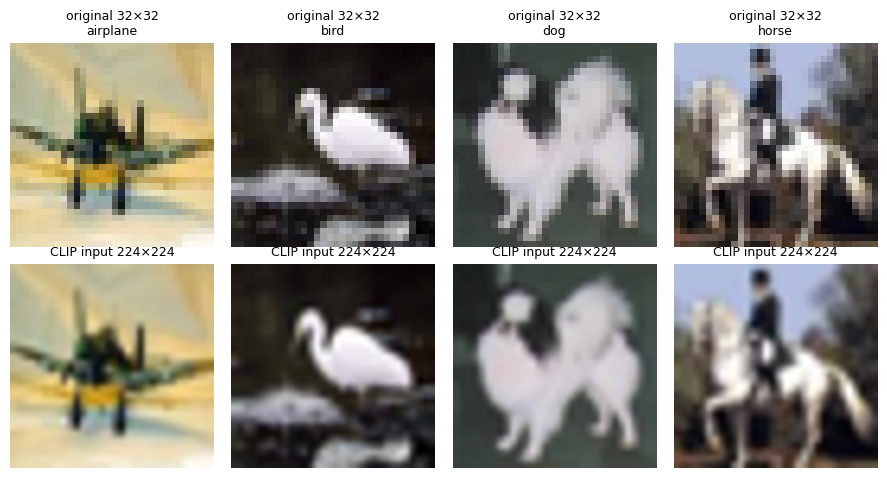

In [6]:
px = processor(images=imgs_A[:8], return_tensors="pt")["pixel_values"]
print("batch of 8 ->", tuple(px.shape), px.dtype, f"| value range [{px.min():.2f}, {px.max():.2f}] (normalized)")
print("mean:", processor.image_processor.image_mean, "std:", processor.image_processor.image_std)

mean = torch.tensor(processor.image_processor.image_mean).view(3, 1, 1)
std = torch.tensor(processor.image_processor.image_std).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(9, 4.8))
for j in range(4):
    axes[0, j].imshow(imgs_A[j * 250]); axes[0, j].set_title(f"original 32×32\n{CLASSES[y_A[j*250]]}", fontsize=9)
    p = processor(images=[imgs_A[j * 250]], return_tensors="pt")["pixel_values"][0]
    axes[1, j].imshow((p * std + mean).clamp(0, 1).permute(1, 2, 0)); axes[1, j].set_title("CLIP input 224×224", fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.savefig("figures/preprocessing.png", dpi=120); plt.show()

## 5. Extract and normalize embeddings

In [7]:
t0 = time.time()
img_emb_A = embed_images(imgs_A)                  # (1000, 512), unit norm
txt_emb = embed_texts([CAPTION])                  # (1, 512), unit norm
print(f"image embeddings {tuple(img_emb_A.shape)} in {time.time()-t0:.1f}s | text embedding {tuple(txt_emb.shape)}")
norms = img_emb_A.norm(dim=-1)
print(f"image norms after normalization: min {norms.min():.4f}, max {norms.max():.4f} | text norm {txt_emb.norm():.4f}")

image embeddings (1000, 512) in 15.4s | text embedding (1, 512)
image norms after normalization: min 1.0000, max 1.0000 | text norm 1.0000


## 6. Compute similarity scores

With unit vectors, **cosine similarity = dot product**: `s_i = img_i · text`. CLIP's raw cosine scores for matching pairs are typically only around 0.25–0.35 (they are not probabilities); what matters is the *ranking*. The table also reports CLIP's scaled logit `100 · s_i`, the quantity CLIP feeds to a softmax.

In [8]:
sim_A = (img_emb_A @ txt_emb.T).squeeze(1).numpy()           # (1000,)
dfA = pd.DataFrame({"idx_in_test": idx_A, "class": [CLASSES[c] for c in y_A], "cosine": sim_A,
                    "clip_logit": sim_A * model.logit_scale.exp().item()})
dfA["rank"] = dfA["cosine"].rank(ascending=False).astype(int)
dfA.to_csv("data/partA_similarity_scores.csv", index=False)
print(f"cosine similarity over 1000 images: min {sim_A.min():.4f}  mean {sim_A.mean():.4f}  max {sim_A.max():.4f}")
dfA.sort_values("rank").head(10)

cosine similarity over 1000 images: min 0.1628  mean 0.2203  max 0.2854


,idx_in_test,class,cosine,clip_logit,rank
562,8424,dog,0.285376,28.537619,1
585,3748,dog,0.283654,28.365442,2
578,4182,dog,0.283514,28.351414,3
568,7149,dog,0.279914,27.991369,4
535,1235,dog,0.279064,27.906399,5
509,3290,dog,0.278103,27.810349,6
572,4390,dog,0.277899,27.789928,7
597,7137,dog,0.276353,27.635254,8
559,991,dog,0.275260,27.526005,9
463,223,deer,0.274303,27.430307,10


Per-class statistics of the similarity to *“a photo of a dog”* (sorted by mean):

In [9]:
per_class_A = (dfA.groupby("class")["cosine"].agg(["mean", "std", "min", "max"])
               .sort_values("mean", ascending=False).round(4))
dog = CLASSES.index("dog")
is_dog = (y_A == dog)
top100 = np.argsort(-sim_A)[:100]
p_at_100 = is_dog[top100].mean()
auc = roc_auc_score(is_dog, sim_A)
print(f"Retrieval view: of the top-100 images by similarity, {is_dog[top100].sum()} are dogs (precision@100 = {p_at_100:.2f}); "
      f"ROC-AUC dog-vs-rest = {auc:.3f}")
print("classes in the top-100:", pd.Series([CLASSES[c] for c in y_A[top100]]).value_counts().to_dict())
per_class_A

Retrieval view: of the top-100 images by similarity, 77 are dogs (precision@100 = 0.77); ROC-AUC dog-vs-rest = 0.979
classes in the top-100: {'dog': 77, 'deer': 10, 'cat': 8, 'bird': 4, 'horse': 1}


,mean,std,min,max
class,,,,
dog,0.2616,0.0101,0.2316,0.2854
cat,0.2389,0.0125,0.1929,0.2655
deer,0.2326,0.0138,0.2013,0.2743
frog,0.2307,0.0131,0.1798,0.2542
bird,0.2258,0.0139,0.1982,0.2592
horse,0.2219,0.0135,0.1898,0.2604
automobile,0.2015,0.0112,0.1698,0.2375
airplane,0.2013,0.0139,0.1628,0.2339
truck,0.1959,0.0102,0.1759,0.2180


## 7. Visualize the results — images alongside their similarity scores

Below: the 15 highest- and 15 lowest-scoring images (green title = a dog, red = not a dog), then the score distribution for each class.

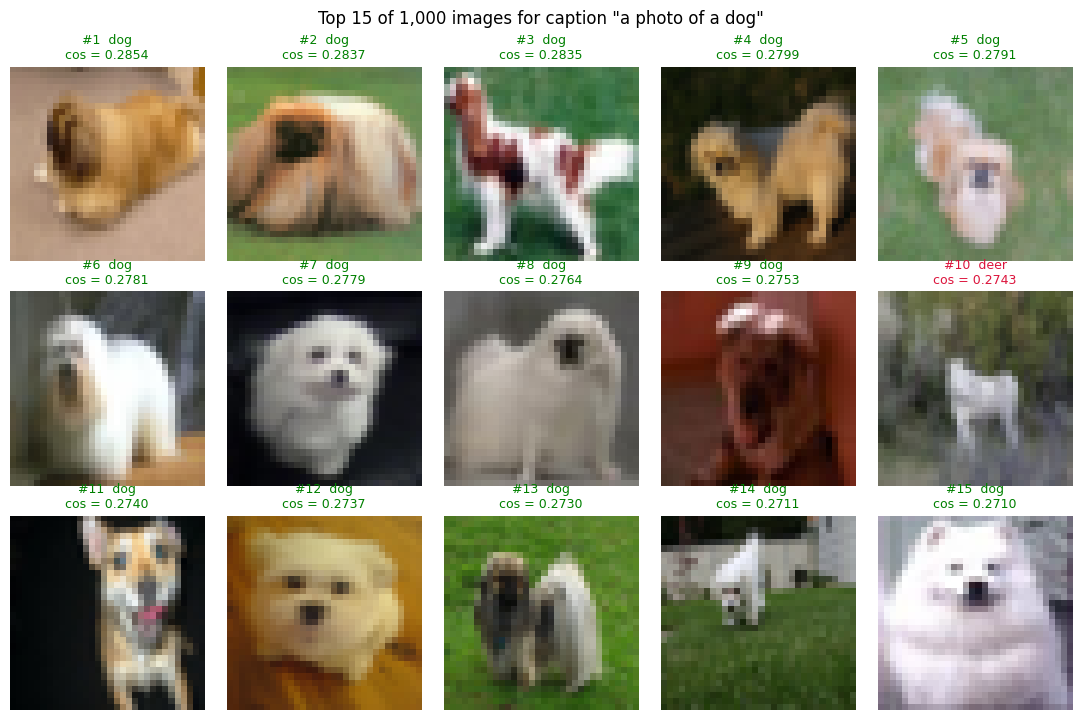

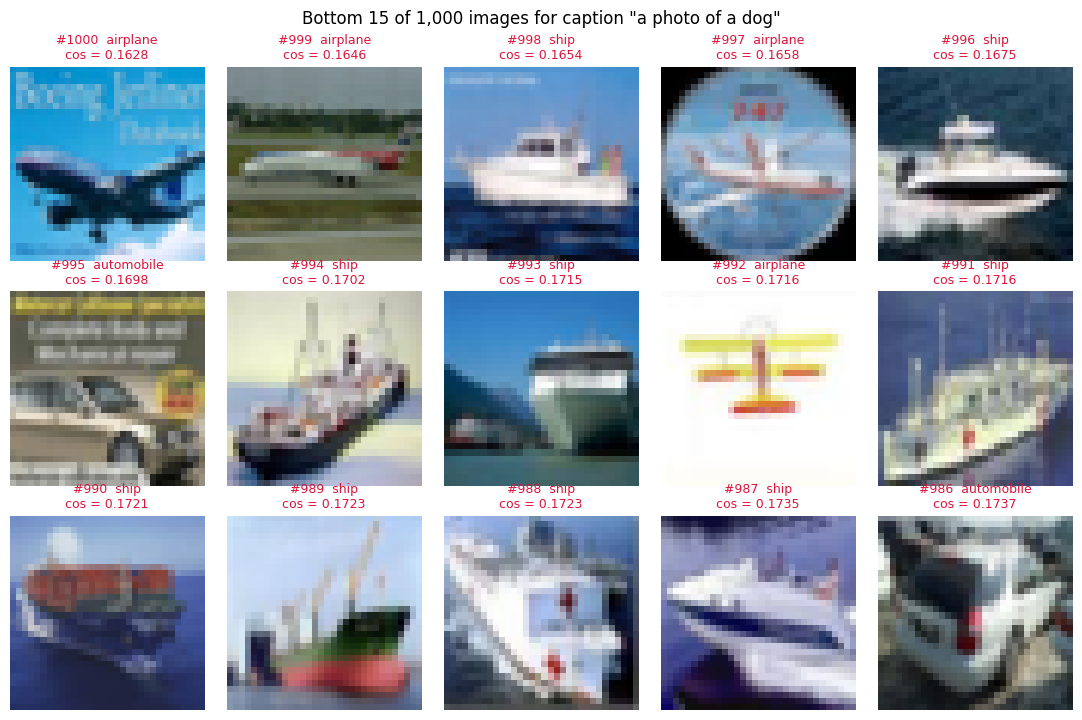

In [10]:
def show_ranked(order, title, fname):
    fig, axes = plt.subplots(3, 5, figsize=(11, 7.3))
    for ax, i in zip(axes.flat, order):
        ax.imshow(imgs_A[i]); ax.axis("off")
        ax.set_title(f"#{dfA['rank'][i]}  {CLASSES[y_A[i]]}\ncos = {sim_A[i]:.4f}", fontsize=9,
                     color="green" if y_A[i] == dog else "crimson")
    plt.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()

order = np.argsort(-sim_A)
show_ranked(order[:15], f'Top 15 of 1,000 images for caption "{CAPTION}"', "figures/partA_top15.png")
show_ranked(order[-15:][::-1], f'Bottom 15 of 1,000 images for caption "{CAPTION}"', "figures/partA_bottom15.png")

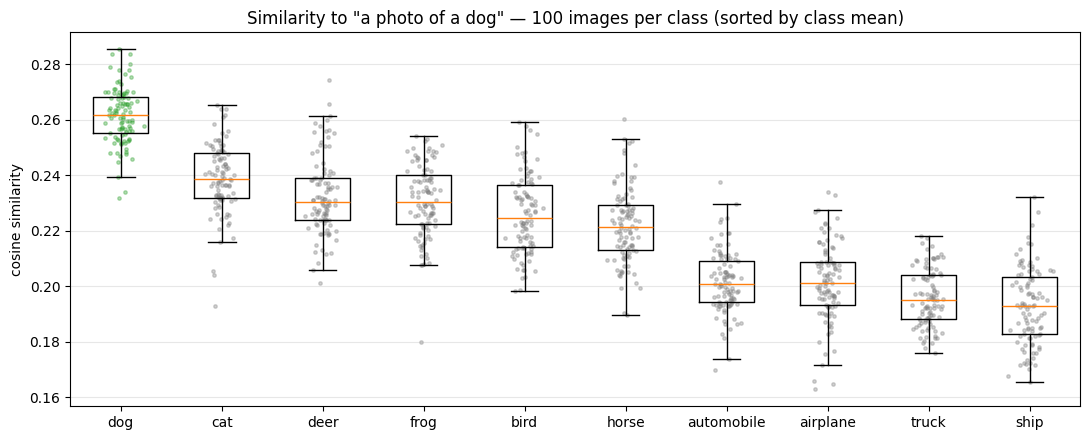

In [11]:
order_cls = per_class_A.index.tolist()
fig, ax = plt.subplots(figsize=(11, 4.5))
data = [dfA.loc[dfA["class"] == c, "cosine"].values for c in order_cls]
ax.boxplot(data, showfliers=False, widths=0.55)
for k, d in enumerate(data, start=1):
    ax.scatter(np.random.normal(k, 0.07, len(d)), d, s=6, alpha=0.35,
               color="tab:green" if order_cls[k-1] == "dog" else "tab:gray")
ax.set_xticks(range(1, 11)); ax.set_xticklabels(order_cls)
ax.set_ylabel("cosine similarity"); ax.set_title(f'Similarity to "{CAPTION}" — 100 images per class (sorted by class mean)')
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.savefig("figures/partA_per_class_boxplot.png", dpi=120); plt.show()

### 7b. Additional captions

To check that the behaviour is not specific to one caption, the same 1,000 image embeddings are scored against several more captions, including ones that name a *group* of classes or a property rather than a class. The heatmap shows the mean cosine similarity per class; each row is centred (row mean subtracted) so that rows are comparable.

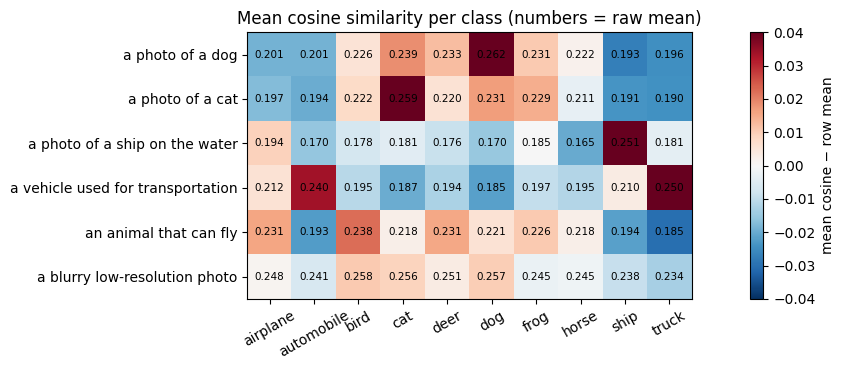

,caption,best class (mean),worst class (mean),top-100 composition
0,a photo of a dog,dog,ship,"{'dog': 77, 'deer': 10, 'cat': 8, 'bird': 4}"
1,a photo of a cat,cat,truck,"{'cat': 73, 'dog': 13, 'deer': 6, 'frog': 4}"
2,a photo of a ship on the water,ship,horse,"{'ship': 92, 'airplane': 3, 'truck': 2, 'deer'..."
3,a vehicle used for transportation,truck,dog,"{'truck': 66, 'automobile': 34}"
4,an animal that can fly,bird,truck,"{'bird': 35, 'airplane': 29, 'deer': 20, 'frog..."
5,a blurry low-resolution photo,bird,truck,"{'cat': 27, 'dog': 22, 'bird': 21, 'airplane':..."


In [12]:
CAPTIONS = ["a photo of a dog", "a photo of a cat", "a photo of a ship on the water",
            "a vehicle used for transportation", "an animal that can fly", "a blurry low-resolution photo"]
txt_multi = embed_texts(CAPTIONS)
S = (img_emb_A @ txt_multi.T).numpy()                         # (1000, n_captions)
heat = pd.DataFrame([[S[y_A == c, j].mean() for c in range(10)] for j in range(len(CAPTIONS))],
                    index=CAPTIONS, columns=CLASSES)
centred = heat.sub(heat.mean(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(centred.values, cmap="RdBu_r", vmin=-0.04, vmax=0.04)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=30)
ax.set_yticks(range(len(CAPTIONS))); ax.set_yticklabels(CAPTIONS)
for j in range(len(CAPTIONS)):
    for c in range(10):
        ax.text(c, j, f"{heat.values[j, c]:.3f}", ha="center", va="center", fontsize=7.5)
plt.colorbar(im, label="mean cosine − row mean"); ax.set_title("Mean cosine similarity per class (numbers = raw mean)")
plt.tight_layout(); plt.savefig("figures/partA_caption_heatmap.png", dpi=120); plt.show()

rows = []
for j, cap in enumerate(CAPTIONS):
    top = np.argsort(-S[:, j])[:100]
    rows.append({"caption": cap, "best class (mean)": heat.columns[heat.values[j].argmax()],
                 "worst class (mean)": heat.columns[heat.values[j].argmin()],
                 "top-100 composition": pd.Series([CLASSES[c] for c in y_A[top]]).value_counts().head(4).to_dict()})
pd.DataFrame(rows)

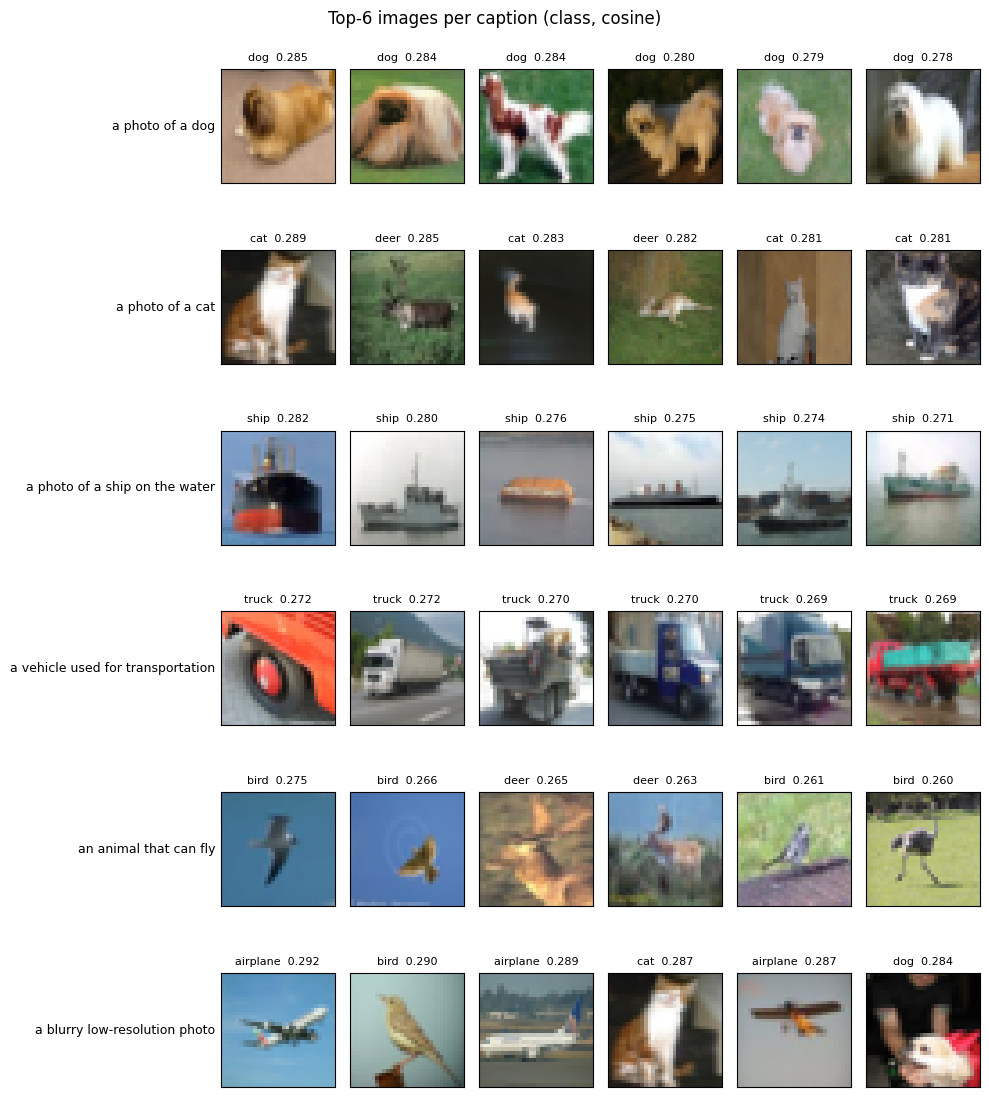

In [13]:
fig, axes = plt.subplots(len(CAPTIONS), 6, figsize=(10, 1.9 * len(CAPTIONS)))
for j, cap in enumerate(CAPTIONS):
    for k, i in enumerate(np.argsort(-S[:, j])[:6]):
        ax = axes[j, k]; ax.imshow(imgs_A[i]); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{CLASSES[y_A[i]]}  {S[i, j]:.3f}", fontsize=8)
    axes[j, 0].set_ylabel(cap, rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("Top-6 images per caption (class, cosine)"); plt.tight_layout()
plt.savefig("figures/partA_top6_per_caption.png", dpi=120); plt.show()

# Part B — Zero-shot classification on CIFAR-10

## 8. Build the zero-shot classifier

For each class `c`, embed a text prompt (e.g. *“a photo of a {c}.”*) to get a class weight vector `w_c`. An image with embedding `x` is predicted as `argmax_c (x · w_c)`. No CIFAR-10 image is used to build the classifier.

Three prompt strategies are compared:
1. **bare class name** — `"{c}"`
2. **single template** — `"a photo of a {c}."` (the main result)
3. **prompt ensemble** — the average of the normalized embeddings of 8 templates per class, then renormalized (the technique from the CLIP paper)

In [14]:
CACHE = "data/clip_vitb32_cifar10_test_image_emb.npy"
if os.path.exists(CACHE):
    img_emb_all = torch.from_numpy(np.load(CACHE)); print("loaded cached image embeddings", tuple(img_emb_all.shape))
else:
    t0 = time.time(); img_emb_all = embed_images(images_all)
    np.save(CACHE, img_emb_all.numpy()); print(f"embedded {len(images_all)} images in {time.time()-t0:.1f}s")

TEMPLATES = ["a photo of a {}.", "a blurry photo of a {}.", "a low resolution photo of a {}.", "a photo of the small {}.",
             "a pixelated photo of a {}.", "a close-up photo of a {}.", "a good photo of a {}.", "an image of a {}."]

def class_weights(templates):
    W = []
    for c in CLASSES:
        e = embed_texts([t.format(c) for t in templates]).mean(0)
        W.append(e / e.norm())
    return torch.stack(W)                                   # (10, 512)

strategies = {"bare class name": ["{}"], "single template": ["a photo of a {}."], "8-template ensemble": TEMPLATES}
preds, logits_by = {}, {}
for name, tpl in strategies.items():
    logits = 100.0 * img_emb_all @ class_weights(tpl).T     # CLIP's logit scale ~100
    logits_by[name] = logits; preds[name] = logits.argmax(1).numpy()
summary = pd.DataFrame({name: {"top-1 accuracy": (p == labels_all).mean(),
                               "top-2 accuracy": np.mean([labels_all[i] in logits_by[name][i].topk(2).indices.numpy() for i in range(len(p))])}
                        for name, p in preds.items()}).T
summary.round(4)

loaded cached image embeddings (10000, 512)


,top-1 accuracy,top-2 accuracy
bare class name,0.8739,0.9528
single template,0.8833,0.9553
8-template ensemble,0.8894,0.9574


## 9. Per-class accuracy

Per-class accuracy = recall of each class = fraction of that class's 1,000 test images predicted correctly. The main result uses the single template *“a photo of a {c}.”*; the ensemble is shown alongside.

In [15]:
MAIN = "single template"
y_pred = preds[MAIN]
pc = pd.DataFrame({name: [(p[labels_all == c] == c).mean() for c in range(10)] for name, p in preds.items()}, index=CLASSES)
pc["n test images"] = np.bincount(labels_all)
pc = pc.sort_values(MAIN, ascending=False)
pc.loc["OVERALL"] = [(p == labels_all).mean() for p in preds.values()] + [len(labels_all)]
pc.to_csv("data/partB_per_class_accuracy.csv")
pc.style.format({k: "{:.1%}" for k in preds}).format({"n test images": "{:.0f}"})

,bare class name,single template,8-template ensemble,n test images
horse,0.971000,0.971000,0.974000,1000
ship,0.964000,0.959000,0.966000,1000
truck,0.942000,0.950000,0.954000,1000
automobile,0.899000,0.933000,0.934000,1000
bird,0.917000,0.898000,0.877000,1000
dog,0.852000,0.891000,0.892000,1000
airplane,0.811000,0.890000,0.903000,1000
cat,0.791000,0.857000,0.858000,1000
deer,0.821000,0.769000,0.788000,1000
frog,0.771000,0.715000,0.748000,1000


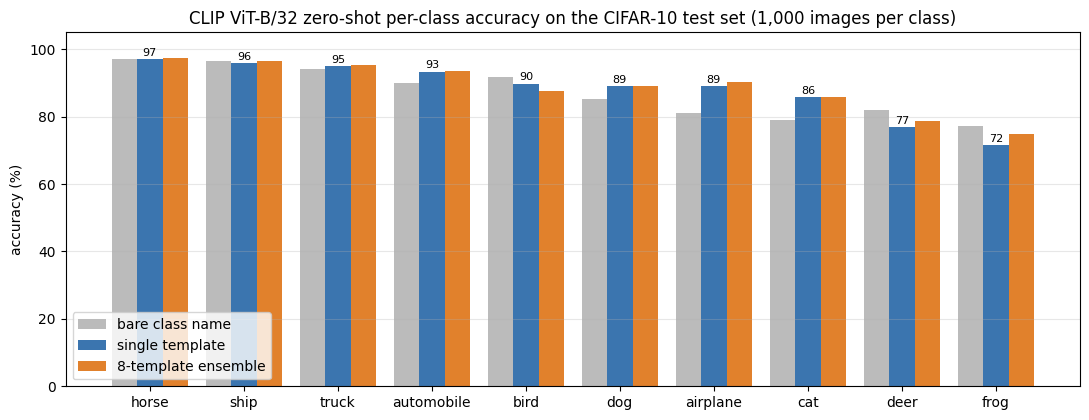

In [16]:
order_b = pc.drop("OVERALL").index.tolist()
x = np.arange(10); w = 0.27
fig, ax = plt.subplots(figsize=(11, 4.3))
for k, (name, col) in enumerate(zip(preds, ["#bbbbbb", "#3b75af", "#e1812c"])):
    vals = pc.loc[order_b, name].values * 100
    bars = ax.bar(x + (k - 1) * w, vals, w, label=name, color=col)
    if name == MAIN:
        ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=1)
ax.set_xticks(x); ax.set_xticklabels(order_b); ax.set_ylabel("accuracy (%)"); ax.set_ylim(0, 105)
ax.set_title("CLIP ViT-B/32 zero-shot per-class accuracy on the CIFAR-10 test set (1,000 images per class)")
ax.legend(loc="lower left"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("figures/partB_per_class_accuracy.png", dpi=120); plt.show()

## 10. Confusion matrix

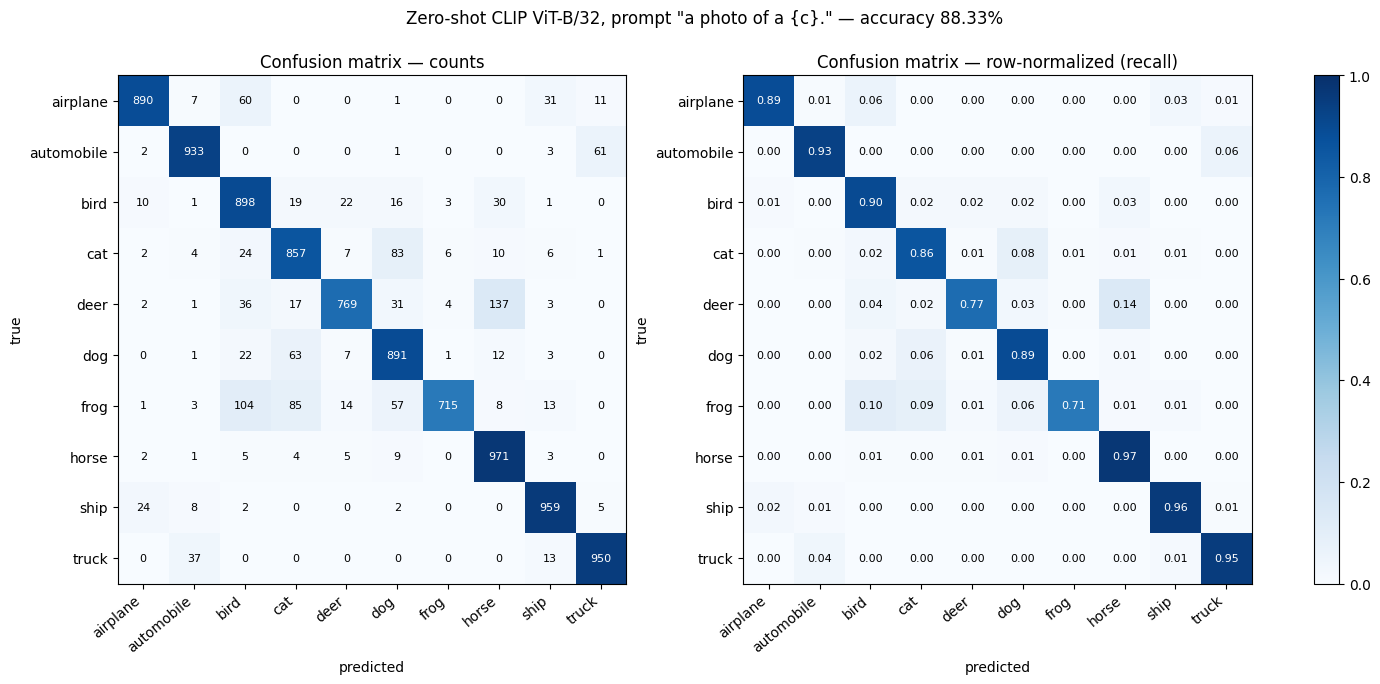

In [17]:
cm = confusion_matrix(labels_all, y_pred, labels=range(10))
cm_norm = cm / cm.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.6))
for ax, M, ttl, fmt in [(axes[0], cm, "counts", "d"), (axes[1], cm_norm, "row-normalized (recall)", ".2f")]:
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=8,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=40, ha="right")
    ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix — {ttl}")
fig.colorbar(im, ax=axes, fraction=0.025)
plt.suptitle(f'Zero-shot CLIP ViT-B/32, prompt "a photo of a {{c}}." — accuracy {(y_pred == labels_all).mean():.2%}')
plt.savefig("figures/partB_confusion_matrix.png", dpi=120, bbox_inches="tight"); plt.show()

In [18]:
print(classification_report(labels_all, y_pred, target_names=CLASSES, digits=3))
off = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(10) for j in range(10) if i != j]
top_conf = pd.DataFrame(sorted(off, key=lambda t: -t[2])[:10], columns=["true", "predicted as", "count"])
top_conf["% of true class"] = (top_conf["count"] / 1000 * 100).round(1)
top_conf

              precision    recall  f1-score   support

    airplane      0.954     0.890     0.921      1000
  automobile      0.937     0.933     0.935      1000
        bird      0.780     0.898     0.835      1000
         cat      0.820     0.857     0.838      1000
        deer      0.933     0.769     0.843      1000
         dog      0.817     0.891     0.852      1000
        frog      0.981     0.715     0.827      1000
       horse      0.831     0.971     0.896      1000
        ship      0.927     0.959     0.943      1000
       truck      0.924     0.950     0.937      1000

    accuracy                          0.883     10000
   macro avg      0.890     0.883     0.883     10000
weighted avg      0.890     0.883     0.883     10000



,true,predicted as,count,% of true class
0,deer,horse,137,13.7
1,frog,bird,104,10.4
2,frog,cat,85,8.5
3,cat,dog,83,8.3
4,dog,cat,63,6.3
5,automobile,truck,61,6.1
6,airplane,bird,60,6.0
7,frog,dog,57,5.7
8,truck,automobile,37,3.7
9,deer,bird,36,3.6


Examples of the most frequent confusions (true → predicted, with the softmax probability of the wrong class):

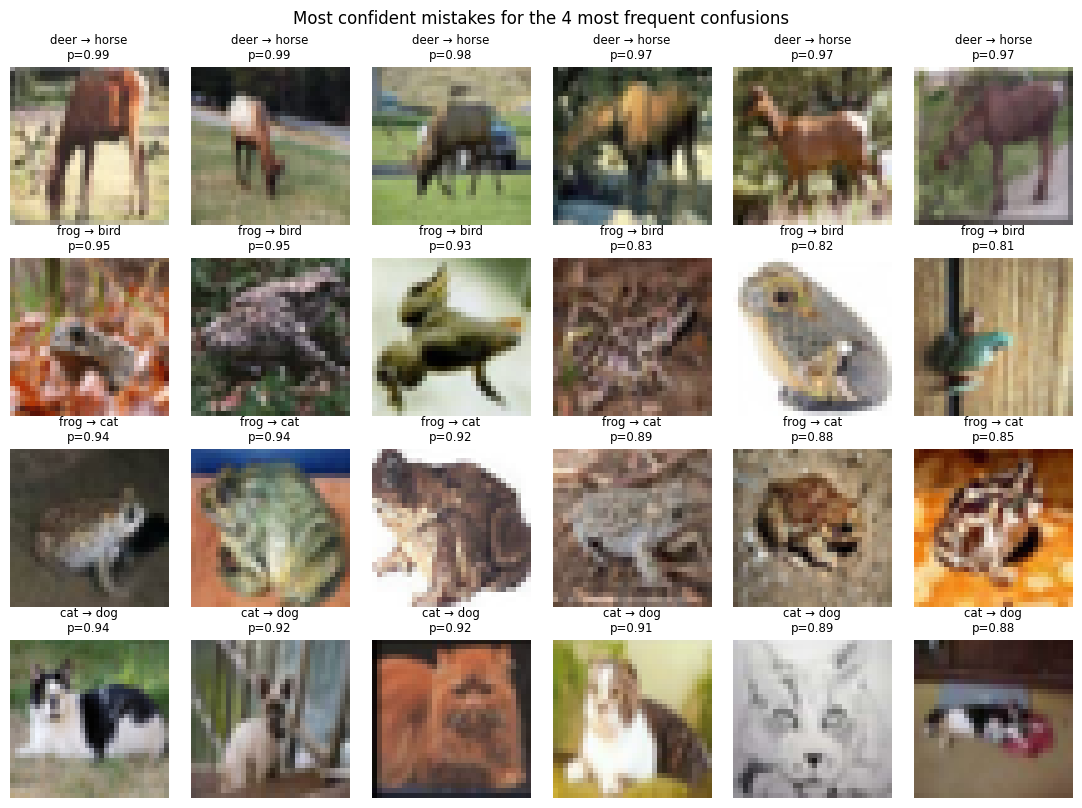

In [19]:
probs = logits_by[MAIN].softmax(1).numpy()
fig, axes = plt.subplots(4, 6, figsize=(11, 8.2))
for r, (t, p_) in enumerate(top_conf.head(4)[["true", "predicted as"]].values):
    ti, pi = CLASSES.index(t), CLASSES.index(p_)
    cand = np.where((labels_all == ti) & (y_pred == pi))[0]
    cand = cand[np.argsort(-probs[cand, pi])][:6]
    for k, i in enumerate(cand):
        ax = axes[r, k]; ax.imshow(images_all[i]); ax.axis("off")
        ax.set_title(f"{t} → {p_}\np={probs[i, pi]:.2f}", fontsize=8.5)
plt.suptitle("Most confident mistakes for the 4 most frequent confusions"); plt.tight_layout()
plt.savefig("figures/partB_mistakes.png", dpi=120); plt.show()

Link back to Part A: a caption-similarity score *is* one column of the zero-shot classifier. The check below confirms that classifying Part A's 1,000 images with Part A's embeddings gives the same predictions as Part B (same model, same images).

In [20]:
W_single = class_weights(["a photo of a {}."])
pred_A = (img_emb_A @ W_single.T).argmax(1).numpy()
print(f"zero-shot accuracy on the Part A subset (100/class): {(pred_A == y_A).mean():.2%}; "
      f"agreement with Part B predictions on the same images: {(pred_A == y_pred[idx_A]).mean():.2%}")

zero-shot accuracy on the Part A subset (100/class): 87.60%; agreement with Part B predictions on the same images: 100.00%


## 11. Findings

The numbers quoted here are from the executed run recorded in `RUN_LOG.txt`/`METRICS.md` (CLIP ViT-B/32, CIFAR-10 test, SEED = 1605).

### Part A — caption vs. 1,000 images (100 per class), caption *“a photo of a dog”*

1. **The ranking is right even though the raw scores are small.** Cosine similarities range only from 0.163 to 0.285 (mean 0.220). CLIP is not calibrated to give 1.0 for a match; the useful signal is the *relative* order. 14 of the top 15 images are dogs (the exception, a deer, ranks #10), and dog is the highest class on average (0.262), 0.023 above the next class.
2. **Retrieval quality:** 77 of the top 100 images are dogs (precision@100 = 0.77), and dog-vs-rest ROC-AUC is **0.979**. The 23 non-dogs in the top 100 are deer (10), cat (8), bird (4) and horse (1): all animals, mostly furry four-legged ones photographed on grass or indoors.
3. **The class order matches visual and semantic similarity:** dog > cat > deer > frog > bird > horse ≫ automobile ≈ airplane > truck > ship. All 6 animal classes score above all 4 vehicle classes. The class distributions overlap heavily (per-class std ≈ 0.010–0.014 against gaps of about 0.004–0.006 between neighbouring animal classes), so a single threshold on the score could not separate dogs cleanly.
4. **Other captions (Section 7b):**
   - Class captions behave the same way. *“a photo of a cat”*: 73 of the top 100 are cats, with dogs the main intruder (13). *“a photo of a ship on the water”*: 92 of 100 are ships, the cleanest result, probably because water is a strong, distinctive background.
   - The group caption *“a vehicle used for transportation”* puts truck (0.250) and automobile (0.240) on top, and its top 100 are 100% cars and trucks (66 + 34). Airplanes and ships are also vehicles but rank much lower (0.212, 0.210): CLIP associates "vehicle" mainly with road vehicles.
   - The property caption *“an animal that can fly”* only half works: bird is the top class (0.238), but airplane and deer are close behind (both 0.231), and its top 100 is only 35 birds against 29 airplanes and 20 deer. CLIP matches "fly" to the *look* of the sky and wings, and does not reason that airplanes are not animals.
   - *“a blurry low-resolution photo”* scores high for **every** class (0.234–0.258, about the level a class caption reaches on its own class, 0.25–0.26). All CIFAR-10 images are blurry when upsampled from 32×32, which shows how much image quality contributes to CLIP's embedding.

### Part B — zero-shot classification of the 10,000 CIFAR-10 test images

5. **Overall accuracy:** **88.33%** top-1 (95.53% top-2) with the single prompt *“a photo of a {c}.”*, without training on any CIFAR-10 image. This is close to the ~88–89% reported for ViT-B/32 on CIFAR-10 in the CLIP paper.
6. **Prompt wording matters a little:** bare class name 87.39% → single template 88.33% (+0.94 pt) → 8-template ensemble 88.94% (+0.61 pt more). The template helps most for airplane (+7.9 pt) and cat (+6.6 pt); it slightly *hurts* bird, deer and frog (−1.9, −5.2, −5.6 pt). The ensemble recovers part of that loss for deer and frog.
7. **Per-class accuracy** (single template): horse 97.1%, ship 95.9%, truck 95.0%, automobile 93.3%, bird 89.8%, dog 89.1%, airplane 89.0%, cat 85.7%, **deer 76.9%**, **frog 71.5%**. Vehicles are easy (89–96%); the hardest classes are small animals photographed against natural backgrounds.
8. **The confusion matrix shows where the errors come from:**
   - **deer → horse (137 images, 13.7% of deer):** the largest single error. Both are brown, four-legged animals on grass, and at 32×32 antlers are often not visible.
   - **Frog is the most scattered class:** frog → bird 104, cat 85, dog 57. Frog has the *highest precision* (98.1%) but the *lowest recall* (71.5%): CLIP rarely calls something a frog unless it is clearly one. The same pattern explains horse's high recall (97.1%) but lower precision (83.1%): horse absorbs deer.
   - **cat ↔ dog (83 + 63)** and **automobile ↔ truck (61 + 37)** are the expected pairs of similar classes. **airplane → bird (60)** comes from the shared sky background, the same confusion seen with *“an animal that can fly”* in Part A.
   - Errors mostly stay inside the animal group or inside the vehicle group: only 124 of the 1,167 errors (10.6%) cross between animals and vehicles, and 70 of those are airplane ↔ bird.
9. **Part A and Part B are the same computation.** The caption similarity of Part A is one column of the zero-shot classifier. On Part A's 1,000 images, the zero-shot predictions agree 100% with Part B's (87.6% accuracy on that subset).

### Limitations
- **Low resolution:** CIFAR-10 images are 32×32 and are upsampled 7× to CLIP's 224×224 input, far from the web photos CLIP was trained on. This, rather than the prompts, is probably the main limit on accuracy.
- **One model only:** results are for ViT-B/32. Larger CLIP models (ViT-L/14) are reported to reach about 95% on CIFAR-10.
- **One run:** the zero-shot results involve no randomness. Only Part A's 100-per-class subset depends on the seed, so its numbers (for example precision@100) move by a few points with a different sample: an earlier run with SEED = 0 gave precision@100 = 0.73 and ROC-AUC 0.966, against 0.77 and 0.979 here.

In [21]:
print("Done.")

Done.
